# 10 - Várias coletas na mesma viagem

O notebook 08 mostrou que, com coleta por bairro, agrupar entregas quase não economiza - mas ali a moto só podia juntar pedidos **do mesmo ponto de coleta**. Aqui a moto pode passar em **restaurantes diferentes** antes de entregar (problema de coleta e entrega, *pickup and delivery*).

**Regras** (`src/logistica_rotas/roteirizacao/coleta_multipla.py`):
- Cada pedido tem o seu restaurante real (`lat_origem`, `lon_origem`) e o seu destino.
- Mesma lógica do despacho dinâmico: margem de 5 min, sem espera no pico, a moto sai ao lotar, ao atingir a espera máxima ou no último minuto que cumpre todos os prazos.
- Sequência ótima por força bruta (coleta sempre antes da entrega): 6 ordens possíveis com 2 pedidos, 90 com 3.
- Um pedido só entra na moto se o caminho conjunto for **mais curto** que as viagens separadas. Sem hub, juntar pode alongar o caminho; essa checagem foi incluída depois que um teste automático pegou o caso.
- Km = caminho da primeira coleta até a última entrega. O deslocamento vazio até o primeiro restaurante não entra (nem aqui, nem nas viagens individuais).

**Pergunta final:** comparando os três modelos de coleta - **hub por cidade**, **coleta no bairro** e **várias coletas** -, onde agrupar entregas compensa?

## 1. Configuração e cenários de várias coletas

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "src"))

from logistica_rotas.ingestao.leitura import carregar_entregas
from logistica_rotas.limpeza.tratamento import CAMINHO_PROCESSED, limpar_entregas, salvar_parquet

pd.set_option("display.float_format", "{:.1f}".format)
pd.set_option("display.width", 140)

if not CAMINHO_PROCESSED.exists():  # Parquet fica fora do Git: gera a partir do CSV se faltar
    salvar_parquet(limpar_entregas(carregar_entregas()), CAMINHO_PROCESSED)
df = pd.read_parquet(CAMINHO_PROCESSED)

from logistica_rotas.ingestao.simulacao import gerar_entregas
from logistica_rotas.roteirizacao.coleta_multipla import simular_coleta_multipla
from logistica_rotas.roteirizacao.despacho import resumo_despacho, simular_despacho
from logistica_rotas.visualizacao import graficos as g

volumes = {"atual": df, "4x": gerar_entregas(n=20_000)}
linhas = []
for nome_volume, base in volumes.items():
    individual = resumo_despacho(simular_coleta_multipla(base, 0, capacidade=1))
    linhas.append({"volume": nome_volume, "cenario": "individual", **individual.to_dict(), "economia_km_pct": 0.0})
    for capacidade in (2, 3):
        for espera in (5, 10):
            entregas = simular_coleta_multipla(base, espera, capacidade=capacidade)
            r = resumo_despacho(entregas, individual["km"])
            agrupadas = (entregas.groupby("viagem")["id_pedido"].transform("size") > 1).mean() * 100
            linhas.append({"volume": nome_volume, "cenario": f"até {capacidade} pedidos, espera {espera} min",
                           **r.to_dict(), "entregas_agrupadas_pct": agrupadas})
multipla = pd.DataFrame(linhas)
multipla[["volume", "cenario", "entregas_por_viagem", "entregas_agrupadas_pct", "economia_km_pct",
          "espera_media_min", "no_prazo_plan_pct", "no_prazo_real_pct"]]

,volume,cenario,entregas_por_viagem,entregas_agrupadas_pct,economia_km_pct,espera_media_min,no_prazo_plan_pct,no_prazo_real_pct
0,atual,individual,1.0,NaN,0.0,0.0,98.9,96.4
1,atual,"até 2 pedidos, espera 5 min",1.0,0.6,0.1,3.8,98.9,94.4
2,atual,"até 2 pedidos, espera 10 min",1.0,0.6,0.1,5.9,98.9,90.8
3,atual,"até 3 pedidos, espera 5 min",1.0,0.6,0.1,3.8,98.9,94.4
4,atual,"até 3 pedidos, espera 10 min",1.0,0.6,0.1,5.9,98.9,90.8
5,4x,individual,1.0,NaN,0.0,0.0,98.8,96.2
6,4x,"até 2 pedidos, espera 5 min",1.0,1.7,0.5,3.2,98.8,94.4
7,4x,"até 2 pedidos, espera 10 min",1.0,1.7,0.5,4.5,98.8,92.2
8,4x,"até 3 pedidos, espera 5 min",1.0,1.7,0.5,3.2,98.8,94.4
9,4x,"até 3 pedidos, espera 10 min",1.0,1.7,0.5,4.5,98.8,92.1


**Leitura:**
- **Quase nenhuma entrega é agrupada.** No volume atual, só 0,6% das entregas viajam junto com outra e a economia é de 0,1% dos km; com 4 vezes o volume, 1,7% e 0,5%. Aumentar a capacidade de 2 para 3 pedidos não muda nada, porque quase nunca há sequer 2 pedidos compatíveis.
- **O prazo não cabe.** Passar em um segundo restaurante soma o desvio e mais 3 minutos de parada antes da primeira entrega. Com prazos de 20 a 35 minutos, a folga acaba.
- **A espera só custa.** Esperar 5 minutos derruba o prazo com variação de 96,4% para 94,4% (atual), praticamente sem economia em troca.

## 2. Os três modelos de coleta lado a lado

Mesma política em todos: margem de 5 min, espera de até 5 min fora do pico, nenhuma no pico. Cada modelo é comparado com as próprias viagens individuais.

In [2]:
resumos = []
for nome_volume, base in volumes.items():
    modelos = {
        "hub por cidade": (lambda b, w, c: simular_despacho(b, w, c, 5, espera_max_pico_min=0, ponto_coleta="hub")),
        "coleta no bairro": (lambda b, w, c: simular_despacho(b, w, c, 5, espera_max_pico_min=0, ponto_coleta="bairro")),
        "várias coletas (até 3)": (lambda b, w, c: simular_coleta_multipla(b, w, capacidade=min(c, 3))),
    }
    for nome_modelo, simular in modelos.items():
        individual = resumo_despacho(simular(base, 0, 1))
        r = resumo_despacho(simular(base, 5, 4), individual["km"])
        resumos.append({"cenario": f"{nome_volume} · {nome_modelo}", **r.to_dict(),
                        "no_prazo_individual": individual["no_prazo_real_pct"]})
comparacao = pd.DataFrame(resumos).set_index("cenario")
comparacao[["entregas_por_viagem", "economia_km_pct", "no_prazo_real_pct", "no_prazo_individual"]]

,entregas_por_viagem,economia_km_pct,no_prazo_real_pct,no_prazo_individual
cenario,,,,
atual · hub por cidade,1.1,1.9,96.4,97.0
atual · coleta no bairro,1.0,0.4,97.6,98.1
atual · várias coletas (até 3),1.0,0.1,94.4,96.4
4x · hub por cidade,1.2,5.7,95.3,97.0
4x · coleta no bairro,1.0,1.3,97.1,98.0
4x · várias coletas (até 3),1.0,0.5,94.4,96.2


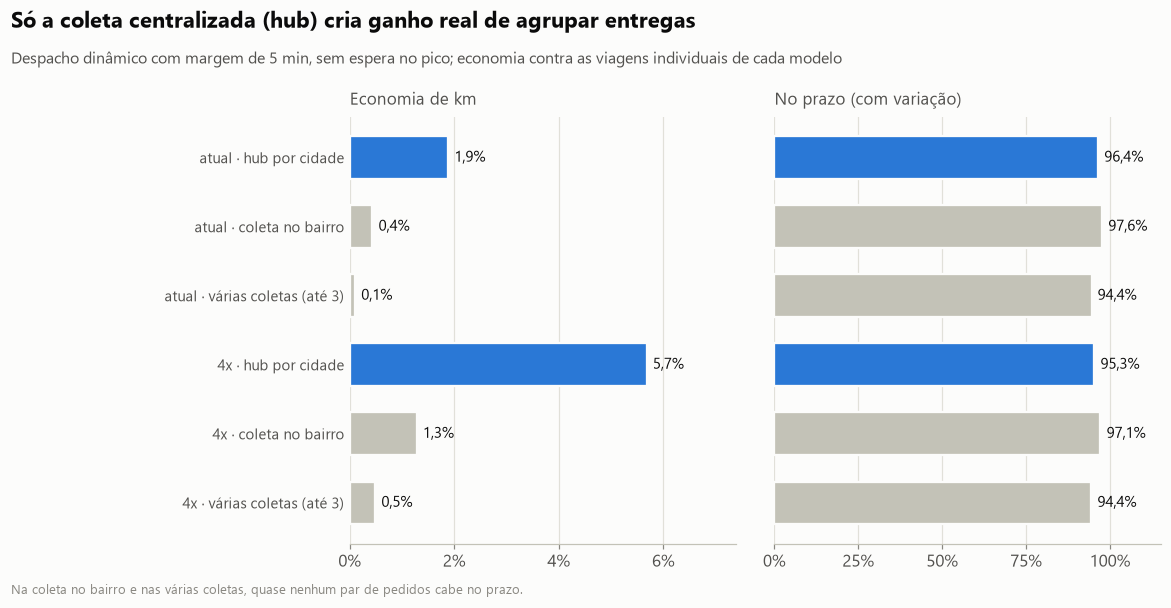

In [3]:
destaques = [c for c in comparacao.index if "hub por cidade" in c]
fig = g.barras_cenarios(comparacao, destaques,
                        "Só a coleta centralizada (hub) cria ganho real de agrupar entregas",
                        "Despacho dinâmico com margem de 5 min, sem espera no pico; economia contra as viagens individuais de cada modelo",
                        "Na coleta no bairro e nas várias coletas, quase nenhum par de pedidos cabe no prazo.")
g.salvar_figura(fig, "16_modelos_de_coleta");

## 3. Conclusões

1. **Várias coletas na mesma viagem não resolvem.** Com prazos de 20 a 35 minutos, passar em dois restaurantes quase nunca cabe no prazo: a economia fica em 0,1% (atual) e 0,5% (4x).
2. **O ganho de agrupar depende de centralizar a coleta.** Só com um hub por cidade aparece economia relevante (1,9% no volume atual, 5,7% com 4 vezes), com perda pequena de prazo.
3. **Sem hub, a melhor política é despachar na hora.** Esperar por um parceiro que quase nunca aparece só consome a folga do prazo.
4. **Para o negócio:** antes de investir em algoritmo de roteirização, a pergunta é operacional: **dá para concentrar a coleta** (dark kitchen, hub de restaurantes, micro centro de distribuição)? Sem isso, o algoritmo tem pouco com o que trabalhar.

**Limitações:** sem tempo de preparo do pedido; deslocamento vazio até o restaurante não modelado; frota ilimitada; perfil de prazo da simulação (12 min + 2,5 min/km) é apertado para várias paradas - com prazos mais longos (por exemplo, entregas de supermercado), o resultado pode ser diferente.